# Homework 6

Austin Oliver | GitHub: awoliver335 | USC ID: 1949137702

I use the official APS split, all 170 predictors, and random seed 552. Package versions and execution instructions are in `requirements.txt` and `README.md`.

## 1. Tree-Based Methods

In [17]:
# Uncomment to install all project dependencies in this kernel.
# %pip install -r requirements.txt

from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_score, recall_score)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from threadpoolctl import threadpool_limits

SEED, N_JOBS = 552, min(4, os.cpu_count() or 1)
DATA_DIR = Path('data')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.float_format', lambda x: f'{x:.6f}')


### (a) APS Failure data

The UCI APS dataset has 60,000 training and 16,000 test observations. I encode APS failures (`pos`) as 1 and unrelated failures (`neg`) as 0; `na` denotes missing values.

In [2]:
def read_aps(filename):
    # Find the header rather than depending on a fixed license-preamble length.
    path = DATA_DIR / filename
    with path.open(encoding='utf-8') as stream:
        header_row = next(i for i, line in enumerate(stream) if line.startswith('class,'))
    frame = pd.read_csv(path, skiprows=header_row, na_values=['na'])
    assert set(frame['class']) == {'neg', 'pos'}
    labels = frame.pop('class').map({'neg': 0, 'pos': 1}).astype('int8')
    return frame.astype('float64'), labels

X_train, y_train = read_aps('aps_failure_training_set.csv')
X_test, y_test = read_aps('aps_failure_test_set.csv')
assert X_train.shape == (60000, 170) and X_test.shape == (16000, 170)
assert X_train.columns.equals(X_test.columns)
assert not X_train.isna().all().any()
assert not X_test.isna().all().any()
assert np.isfinite(X_train.to_numpy()[~X_train.isna().to_numpy()]).all()
assert (X_train.min() >= 0).all() and (X_test.min() >= 0).all()
display(pd.DataFrame({'rows': [len(X_train), len(X_test)],
                      'predictors': [X_train.shape[1], X_test.shape[1]],
                      'missing_cells': [X_train.isna().sum().sum(), X_test.isna().sum().sum()],
                      'rows_with_missing': [X_train.isna().any(axis=1).sum(),
                                            X_test.isna().any(axis=1).sum()]},
                     index=['Training', 'Test']))

,rows,predictors,missing_cells,rows_with_missing
Training,60000,170,850015,59409
Test,16000,170,228680,15835


### (b) Data preparation
#### (i) Missing values

Common methods include mean/median replacement, KNN, iterative prediction, and multiple imputation to represent uncertainty. I use medians for computational efficiency and resistance to extreme values; constant replacement can still distort variability and associations. Deleting incomplete rows would discard too much data.

Following homework footnote 1, training and official test data use their own column medians. During CV, preprocessing and SMOTE are fitted only within training folds. Test labels never enter model selection. Independent test imputation follows the assignment rather than the usual deployment convention of retaining training medians.

In [3]:
eda_imputer = SimpleImputer(strategy='median')
X_train_imputed = pd.DataFrame(eda_imputer.fit_transform(X_train),
                               columns=X_train.columns, index=X_train.index)
# Use test-set medians as specified in the homework footnote.
X_test_imputed = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_test),
                              columns=X_test.columns, index=X_test.index)
assert X_train_imputed.notna().all().all() and X_test_imputed.notna().all().all()


#### (ii) Coefficient of variation

The table reports all 170 training-feature coefficients, $CV_j=s_j/\bar{x}_j$, after imputation; $s_j$ uses denominator $n-1$. Zero-mean features have undefined CV and are excluded from ranking.

In [4]:
feature_stats = pd.DataFrame({'mean': X_train_imputed.mean(),
                              'sample_std': X_train_imputed.std(ddof=1)})
feature_stats['CV'] = feature_stats['sample_std'] / feature_stats['mean'].replace(0, np.nan)
feature_stats = feature_stats.sort_values('CV', ascending=False, na_position='last')
assert len(feature_stats) == 170 and feature_stats.CV.notna().all()
# Read down each feature/CV pair, then move right; all 170 values are shown.
cv_rows = feature_stats['CV'].rename_axis('Feature').reset_index()
blocks = [cv_rows.iloc[i:i+43].reset_index(drop=True) for i in range(0, 170, 43)]
cv_display = pd.concat([b.add_suffix(f' {j+1}') for j, b in enumerate(blocks)], axis=1)
display(cv_display.style.hide(axis='index').format(precision=6, na_rep=''))


Feature 1,CV 1,Feature 2,CV 2,Feature 3,CV 3,Feature 4,CV 4
cf_000,244.887517,az_007,16.229427,cs_004,4.684803,ee_003,2.572972
co_000,244.507385,cl_000,14.970730,eb_000,4.539892,cc_000,2.524251
ad_000,244.322816,cz_000,14.505585,de_000,4.527525,bx_000,2.511563
cs_009,237.930554,cp_000,13.933288,cn_003,4.192159,cs_005,2.510337
dh_000,123.216097,az_002,13.271741,cg_000,4.025089,aa_000,2.450938
dj_000,117.494225,ay_005,12.524655,ax_000,4.019051,by_000,2.449849
ag_000,92.917755,di_000,11.826232,ay_008,3.815682,bt_000,2.447912
as_000,87.332500,ar_000,11.354347,cs_001,3.663054,bb_000,2.405198
ay_009,84.733735,cn_001,11.262561,dv_000,3.587371,bu_000,2.404997
ak_000,80.424975,cj_000,11.069531,bj_000,3.575794,bv_000,2.404997


#### (iii) Correlation matrix

Pearson correlations use all 170 imputed training features. Every fifth axis label is shown; gray indicates undefined correlations for constant features.

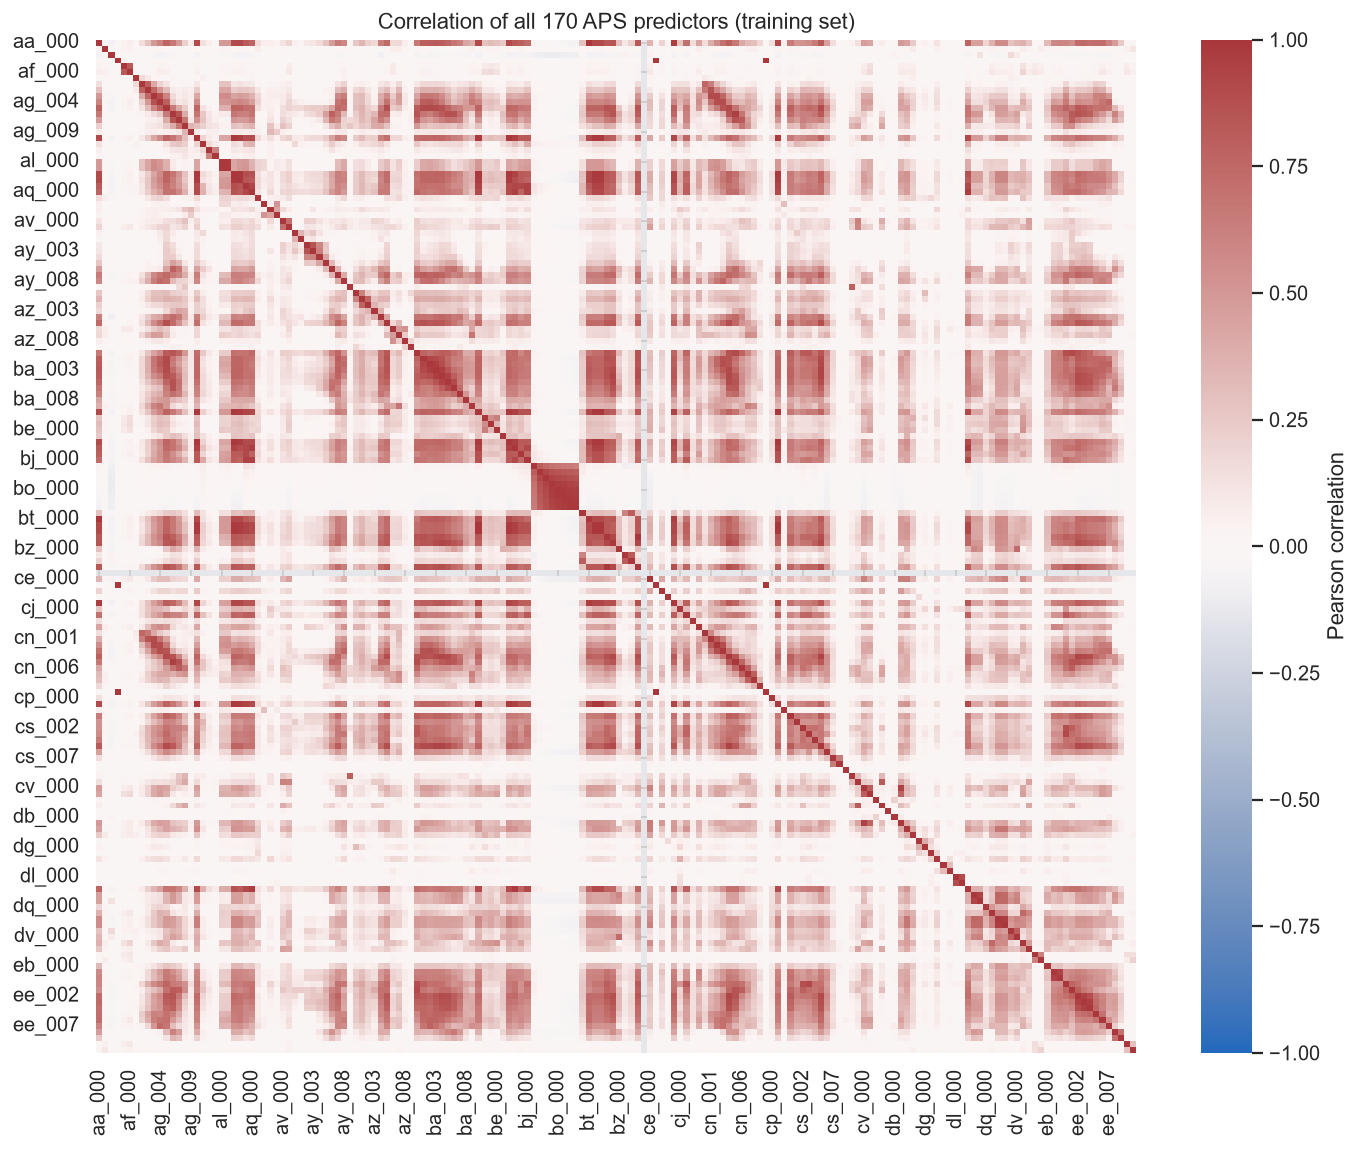

In [5]:
corr = X_train_imputed.corr()
fig, ax = plt.subplots(figsize=(11, 9))
ax.set_facecolor('#e5e7eb')
sns.heatmap(corr, ax=ax, cmap='vlag', center=0, vmin=-1, vmax=1,
            xticklabels=5, yticklabels=5, cbar_kws={'label': 'Pearson correlation'})
ax.set(title='Correlation of all 170 APS predictors (training set)')
plt.tight_layout()
plt.show()


#### (iv) Highest-CV features

The scatter matrix and box plots show the top $\lfloor\sqrt{170}\rfloor=13$ features and all 60,000 training rows. I plot $\log(1+x)$ for readability but calculate CV on the original imputed scale. All 170 predictors remain in the models.

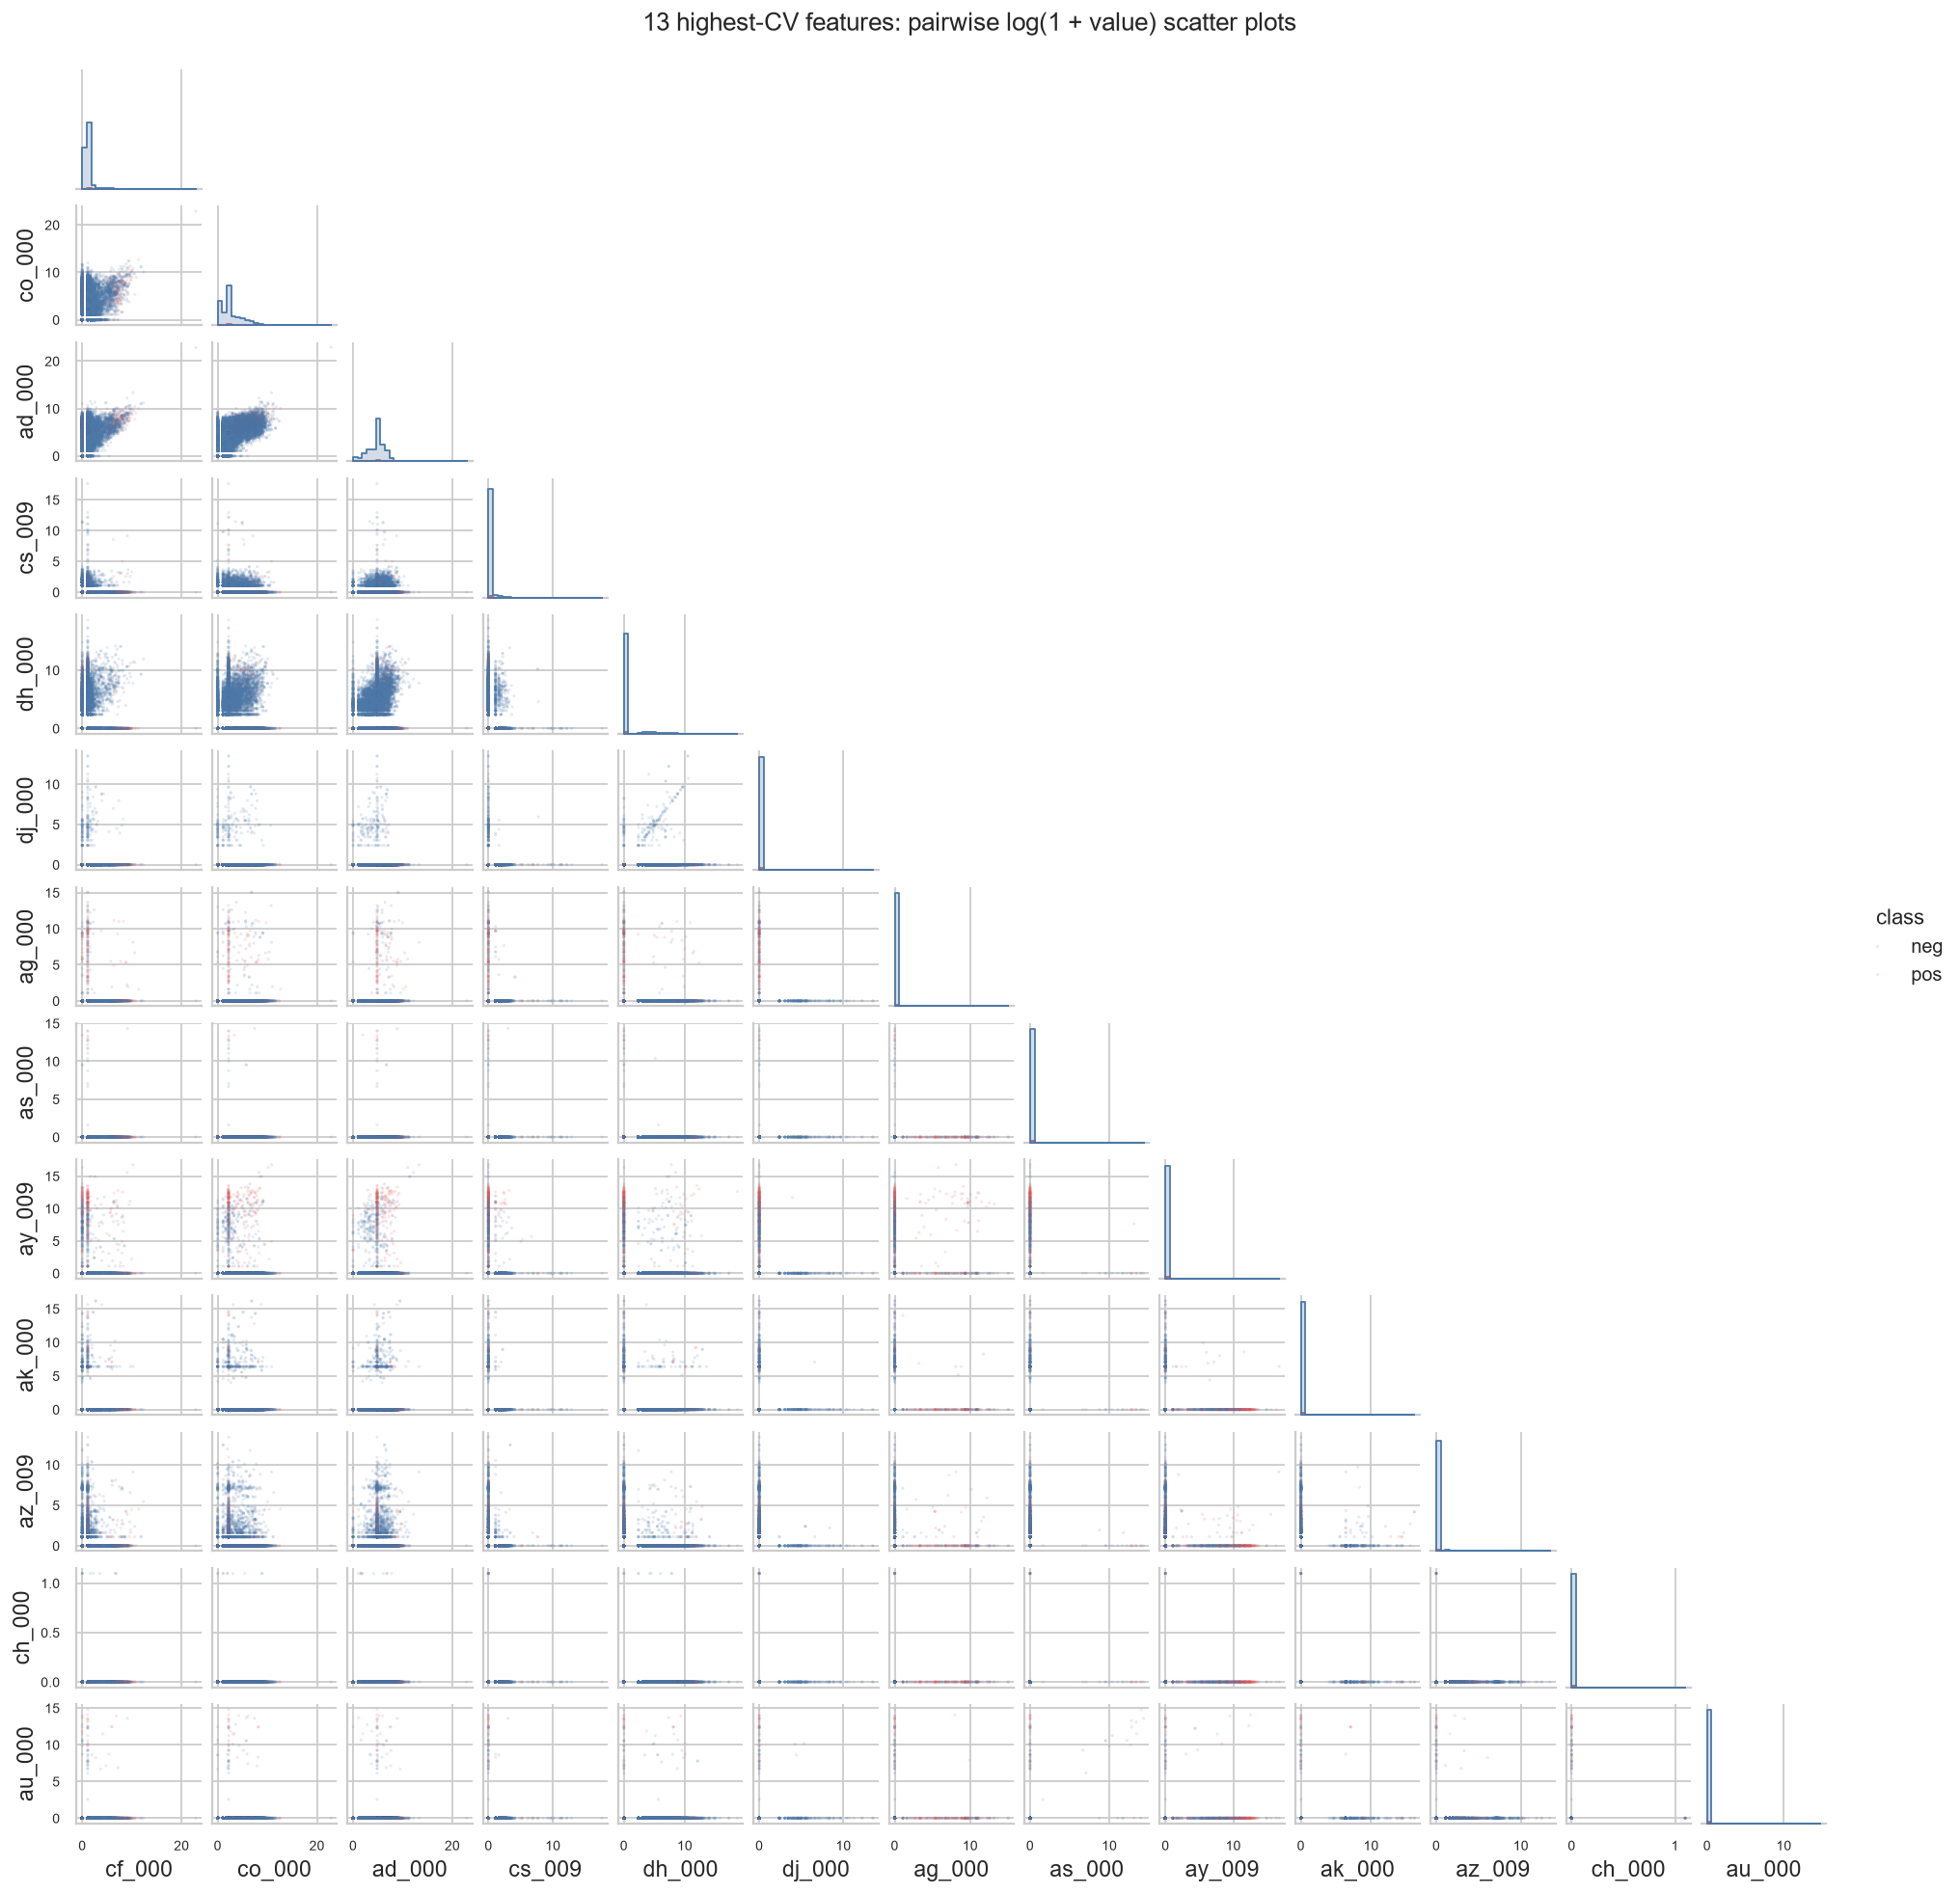

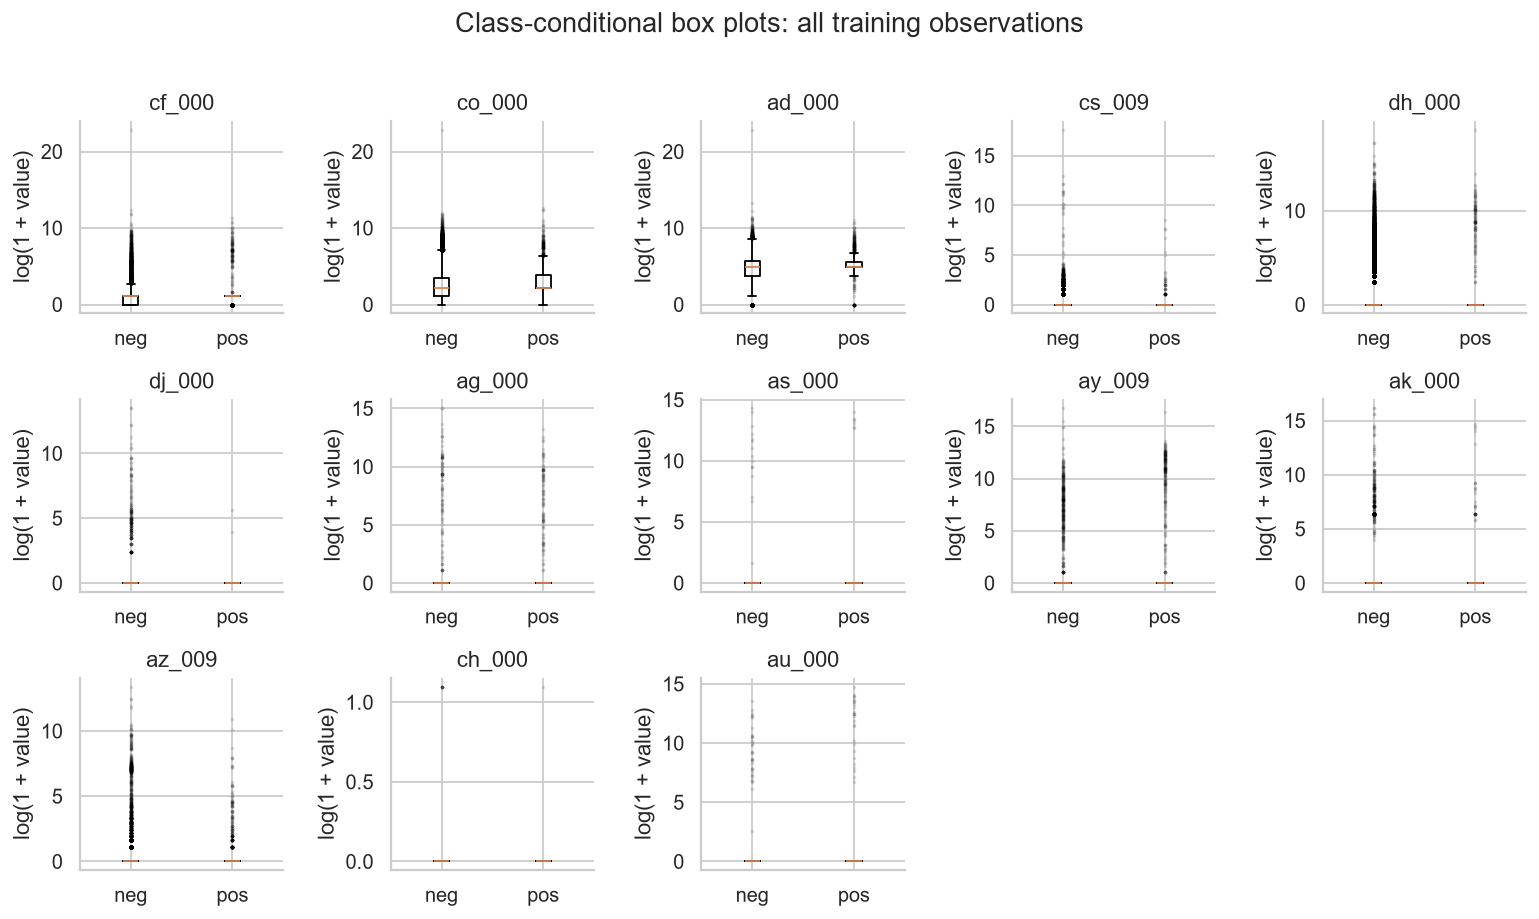

In [6]:
top_features = feature_stats['CV'].dropna().head(int(np.sqrt(X_train.shape[1]))).index.tolist()
scatter_data = np.log1p(X_train_imputed[top_features])
scatter_data['class'] = y_train.map({0: 'neg', 1: 'pos'})
g = sns.pairplot(scatter_data, vars=top_features, hue='class', hue_order=['neg', 'pos'],
                 palette={'neg': '#4c78a8', 'pos': '#e45756'}, corner=True,
                 diag_kind='hist', height=1.15,
                 plot_kws={'s': 3, 'alpha': 0.15, 'linewidth': 0},
                 diag_kws={'bins': 25, 'element': 'step'})
g.set(xlabel=None, ylabel=None)
for i, feature in enumerate(top_features):
    g.axes[-1, i].set_xlabel(feature, fontsize=13)
    g.axes[i, 0].set_ylabel(feature, fontsize=13)
g.tick_params(labelsize=8)
g.fig.suptitle('13 highest-CV features: pairwise log(1 + value) scatter plots', y=1.015)
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(12, 7.2))
for ax, feature in zip(axes.flat, top_features):
    values = [np.log1p(X_train_imputed.loc[y_train == label, feature]) for label in [0, 1]]
    ax.boxplot(values, tick_labels=['neg', 'pos'], showfliers=True,
               flierprops={'markersize': 1, 'alpha': 0.12})
    ax.set(title=feature, ylabel='log(1 + value)')
for ax in list(axes.flat)[len(top_features):]:
    ax.set_visible(False)
fig.suptitle('Class-conditional box plots: all training observations', fontsize=15)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()


Many features concentrate near zero with long upper tails; `co_000` and `ad_000` also appear associated. For `co_000`, both class medians are 8, but the upper quartiles are 32 (`neg`) and 46 (`pos`). The overlap and sensitivity of CV to small means and outliers preclude conclusions about statistical significance or conditional predictive value from these plots alone.

#### (v) Class imbalance

In [7]:
class_counts = pd.DataFrame({'Training': y_train.value_counts(), 'Test': y_test.value_counts()})
class_counts.index = class_counts.index.map({0: 'neg', 1: 'pos'})
display(class_counts.reindex(['neg', 'pos']))


,Training,Test
class,,
neg,59000,15625
pos,1000,375


The 59:1 training ratio is severely imbalanced: always predicting `neg` achieves 98.33% accuracy while missing every failure. I therefore report recall and precision alongside error and ROC AUC. All classification metrics use $\hat p\ge0.5$ as the positive decision rule.

### (c) Random forest without class weighting

I fit 300 unrestricted bootstrap trees with 13 candidate predictors per split, without class weighting or resampling. Confusion matrices use true-class rows and predicted-class columns (`neg`, `pos`); ROC/AUC use probabilities. Training metrics are resubstitution estimates, and test metrics follow the independent-median convention above.

,error,ROC_AUC,recall_pos,precision_pos
Train,0.000000,1.000000,1.000000,1.000000
Test,0.007625,0.994446,0.720000,0.940767


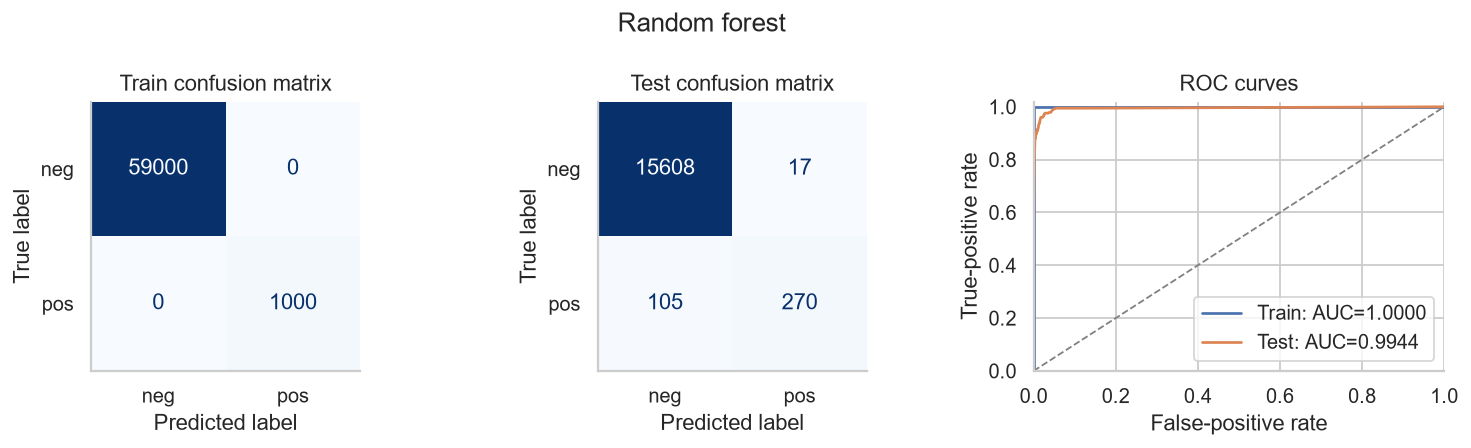

The OOB error is 0.577%, compared with a test error of 0.762%. Test minus OOB is +0.186 percentage points.

In [8]:
all_results = {}
fitted_models = {}

def metric_row(y, probability):
    prediction = (np.asarray(probability) >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {'error': 1 - accuracy_score(y, prediction),
            'ROC_AUC': roc_auc_score(y, probability),
            'recall_pos': recall_score(y, prediction, zero_division=0),
            'precision_pos': precision_score(y, prediction, zero_division=0),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}

def evaluate_model(name, model):
    probabilities = {'Train': model.predict_proba(X_train)[:, 1],
                     'Test': model.predict_proba(X_test_imputed)[:, 1]}
    rows = {split: metric_row(y, probabilities[split])
            for split, y in [('Train', y_train), ('Test', y_test)]}
    result = pd.DataFrame.from_dict(rows, orient='index')
    all_results[name] = result
    fitted_models[name] = model
    display(result[['error', 'ROC_AUC', 'recall_pos', 'precision_pos']])
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, (split, y) in zip(axes[:2], [('Train', y_train), ('Test', y_test)]):
        cm = confusion_matrix(y, probabilities[split] >= 0.5, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=['neg', 'pos']).plot(
            ax=ax, colorbar=False, cmap='Blues', values_format='d')
        ax.set_title(f'{split} confusion matrix')
        ax.grid(False)
        fpr, tpr, _ = roc_curve(y, probabilities[split])
        axes[2].plot(fpr, tpr, label=f'{split}: AUC={rows[split]["ROC_AUC"]:.4f}')
    axes[2].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
    axes[2].set(xlabel='False-positive rate', ylabel='True-positive rate',
                title='ROC curves', xlim=(0, 1), ylim=(0, 1.02))
    axes[2].legend(loc='lower right')
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()
    return result

def make_forest(class_weight=None):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(n_estimators=300, max_features='sqrt',
                                              bootstrap=True, oob_score=True,
                                              class_weight=class_weight,
                                              random_state=SEED, n_jobs=N_JOBS))])

rf_plain = make_forest()
rf_plain.fit(X_train, y_train)
rf_plain_results = evaluate_model('Random forest', rf_plain)
rf_plain_oob_probability = rf_plain.named_steps['classifier'].oob_decision_function_[:, 1]
rf_plain_oob_error = np.mean((rf_plain_oob_probability >= 0.5) != y_train)
display(Markdown(
    f'The OOB error is {rf_plain_oob_error:.3%}, compared with a test error of '
    f'{rf_plain_results.loc["Test", "error"]:.3%}. Test minus OOB is '
    f'{100 * (rf_plain_results.loc["Test", "error"] - rf_plain_oob_error):+.3f} '
    'percentage points.'))


Each OOB prediction averages only trees that excluded that observation, using the same 0.5 threshold. OOB error is more informative than training error, but differs from test error because the samples and class prevalence differ and OOB predictions use fewer trees. Since imputation precedes bootstrapping, OOB also does not fully hold out preprocessing.

### (d) Random forest with class weighting

Class weights increase minority contributions to impurity and leaf estimates; balanced bootstraps and over/undersampling instead change training composition. I keep (c)'s settings and use `class_weight='balanced_subsample'`: each bootstrap's class-$k$ weight is $n/(2n_k)$, roughly 59 times larger for positives.

,error,ROC_AUC,recall_pos,precision_pos
Train,0.000000,1.000000,1.000000,1.000000
Test,0.010687,0.993082,0.581333,0.939655


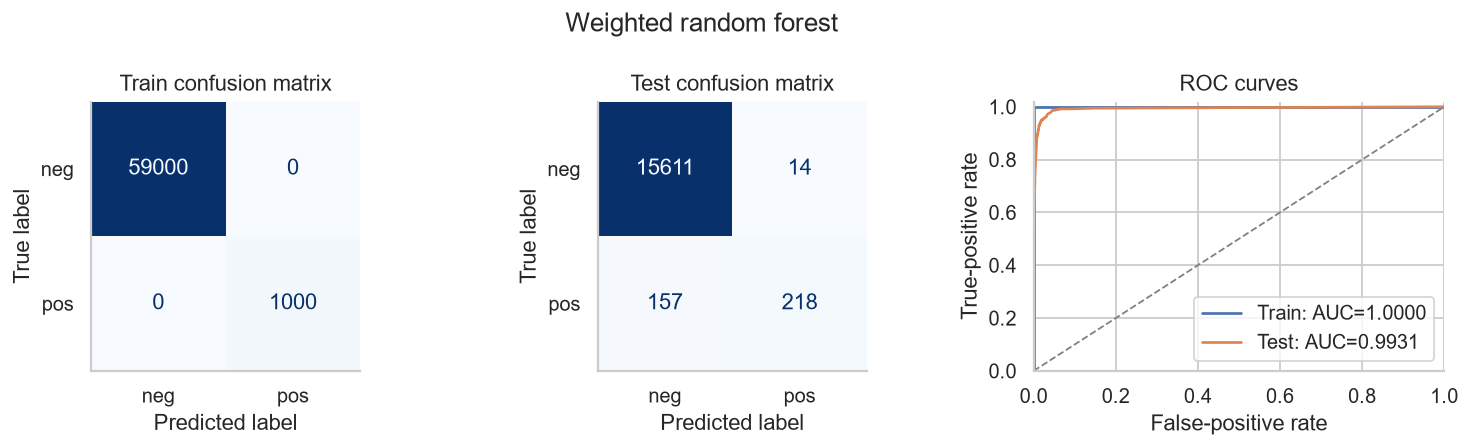

Weighted OOB error is 0.767%, versus test error 1.069%. Weighting changes test error from 0.762% to 1.069% and recall from 72.000% to 58.133%. Missed failures change from 105 to 157, and false alarms from 17 to 14. AUC changes from 0.9944 to 0.9931. Weighting does not improve minority detection in this experiment at the fixed 0.5 threshold.

In [9]:
rf_balanced = make_forest(class_weight='balanced_subsample')
rf_balanced.fit(X_train, y_train)
rf_balanced_results = evaluate_model('Weighted random forest', rf_balanced)
rf_balanced_oob_probability = rf_balanced.named_steps['classifier'].oob_decision_function_[:, 1]
rf_balanced_oob_error = np.mean((rf_balanced_oob_probability >= 0.5) != y_train)
a, b = rf_plain_results.loc['Test'], rf_balanced_results.loc['Test']
recall_effect = 'improves' if b.recall_pos > a.recall_pos else 'does not improve'
display(Markdown(
    f'Weighted OOB error is {rf_balanced_oob_error:.3%}, versus test error {b.error:.3%}. '
    f'Weighting changes test error from {a.error:.3%} to {b.error:.3%} and '
    f'recall from {a.recall_pos:.3%} to {b.recall_pos:.3%}. Missed failures change '
    f'from {int(a.FN)} to {int(b.FN)}, and false alarms from {int(a.FP)} to {int(b.FP)}. '
    f'AUC changes from {a.ROC_AUC:.4f} to {b.ROC_AUC:.4f}. Weighting {recall_effect} '
    'minority detection in this experiment at the fixed 0.5 threshold.'))


### (e) XGBoost logistic model tree

XGBoost has no built-in logistic model tree: `gbtree` uses axis-aligned splits; `gblinear` fits a global linear model. I construct a shallow tree of `gblinear` logistic learners, distinct from standard LogitBoost-based model trees.

The root splits at $p(z)=\sigma(b+z^Tw)=0.5$, then fits local logistic children. I allow one split with at least 200 rows per child; otherwise the root remains a leaf. Pure leaves use observed probabilities. All 170 predictors are median-imputed, $\log(1+x)$-transformed, and standardized, with L1 penalty $\alpha\|w\|_1$ and no L2 penalty.

Five-fold stratified CV selects $\alpha\in\{0,10^{-4},10^{-3},10^{-2},10^{-1}\}$ by mean AUC; error and recall are also reported. Both models use identical folds, 200 rounds, learning rate 0.05, and deterministic coordinate descent with `thrifty` selection of at most 30 eligible coordinates per round. This budget does not guarantee convergence. Preprocessing is refitted per fold; (e) uses no imbalance compensation.

CV error may be optimistic because the folds also select alpha. Test error differs in prevalence and imputation convention; CV training uses 48,000 original rows rather than 60,000.

In [10]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted

ALPHAS = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
cv_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))

class XGBLogisticModelTree(ClassifierMixin, BaseEstimator):
    """One-level oblique routing tree with XGBoost logistic models in its nodes."""
    def __init__(self, reg_alpha=0.0, max_depth=1, min_samples_leaf=200,
                 n_estimators=200, random_state=552):
        self.reg_alpha = reg_alpha
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=np.float64)
        self.classes_ = np.unique(y)
        if not np.array_equal(self.classes_, [0, 1]):
            raise ValueError('This binary estimator requires both labels 0 and 1.')
        self.n_features_in_ = X.shape[1]
        self.nodes_ = []

        def grow(x, target, depth, path):
            node = {'path': path, 'depth': depth, 'rows': len(target),
                    'positives': int(target.sum()), 'left': None, 'right': None,
                    'model': None, 'constant': None}
            self.nodes_.append(node)
            if len(np.unique(target)) == 1:
                node['constant'] = float(target[0])
                return node
            model = XGBClassifier(
                booster='gblinear', objective='binary:logistic', eval_metric='logloss',
                updater='coord_descent', feature_selector='thrifty', top_k=30,
                reg_alpha=self.reg_alpha, reg_lambda=0, learning_rate=.05,
                n_estimators=self.n_estimators, n_jobs=1,
                random_state=self.random_state, verbosity=0)
            model.fit(x, target)
            node['model'] = model
            if depth < self.max_depth:
                left = model.predict_proba(x)[:, 1] < .5
                if min(int(left.sum()), int((~left).sum())) >= self.min_samples_leaf:
                    node['left'] = grow(x[left], target[left], depth+1, path+'/L')
                    node['right'] = grow(x[~left], target[~left], depth+1, path+'/R')
            return node

        self.root_ = grow(X, y, 0, 'root')
        self.n_nodes_ = len(self.nodes_)
        return self

    def predict_proba(self, X):
        check_is_fitted(self, 'root_')
        X = check_array(X, dtype=np.float64)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('Predictor count differs from training.')

        def predict_node(node, x):
            if len(x) == 0:
                return np.empty(0)
            if node['constant'] is not None:
                return np.full(len(x), node['constant'])
            probability = node['model'].predict_proba(x)[:, 1]
            if node['left'] is None:
                return probability
            left = probability < .5
            result = np.empty(len(x))
            result[left] = predict_node(node['left'], x[left])
            result[~left] = predict_node(node['right'], x[~left])
            return result

        probability = predict_node(self.root_, X)
        return np.column_stack([1-probability, probability])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)

def make_model_tree_pipeline(use_smote):
    steps = [('imputer', SimpleImputer(strategy='median')),
             ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
             ('scaler', StandardScaler())]
    if use_smote:
        steps.append(('smote', SMOTE(sampling_strategy=1.0, k_neighbors=5, random_state=SEED)))
    steps.append(('classifier', XGBLogisticModelTree(random_state=SEED)))
    return Pipeline(steps)

def tune_model_tree(use_smote):
    search = GridSearchCV(
        make_model_tree_pipeline(use_smote), {'classifier__reg_alpha': ALPHAS},
        scoring={'roc_auc': 'roc_auc', 'accuracy': 'accuracy', 'recall': 'recall'},
        refit='roc_auc', cv=cv_splits, n_jobs=N_JOBS, pre_dispatch=N_JOBS,
        error_score='raise')
    with threadpool_limits(limits=1):
        search.fit(X_train, y_train)
    cv = pd.DataFrame(search.cv_results_)
    assert np.isfinite(cv[['mean_test_roc_auc', 'mean_test_accuracy']].to_numpy()).all()
    table = pd.DataFrame({'alpha': cv['param_classifier__reg_alpha'].astype(float),
                          'mean_CV_AUC': cv['mean_test_roc_auc'],
                          'mean_CV_error': 1-cv['mean_test_accuracy'],
                          'std_CV_error': cv['std_test_accuracy'],
                          'mean_CV_recall': cv['mean_test_recall']})
    display(table)
    model = search.best_estimator_
    tree = model.named_steps['classifier']
    expected_rows = 118000 if use_smote else 60000
    assert tree.root_['rows'] == expected_rows
    if tree.root_['left'] is not None:
        assert tree.root_['left']['rows'] + tree.root_['right']['rows'] == expected_rows
    probabilities = model.predict_proba(X_train.iloc[:100])
    assert probabilities.shape == (100, 2)
    assert np.allclose(probabilities.sum(axis=1), 1)
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    return search, table


,alpha,mean_CV_AUC,mean_CV_error,std_CV_error,mean_CV_recall
0,0.000000,0.985027,0.009317,0.000731,0.545000
1,0.000100,0.985140,0.009300,0.000660,0.539000
2,0.001000,0.983382,0.009867,0.000915,0.471000
3,0.010000,0.966666,0.012583,0.000858,0.267000
4,0.100000,0.500000,0.016667,0.000000,0.000000


,error,ROC_AUC,recall_pos,precision_pos
Train,0.008317,0.986530,0.561000,0.903382
Test,0.011625,0.992109,0.554667,0.916300


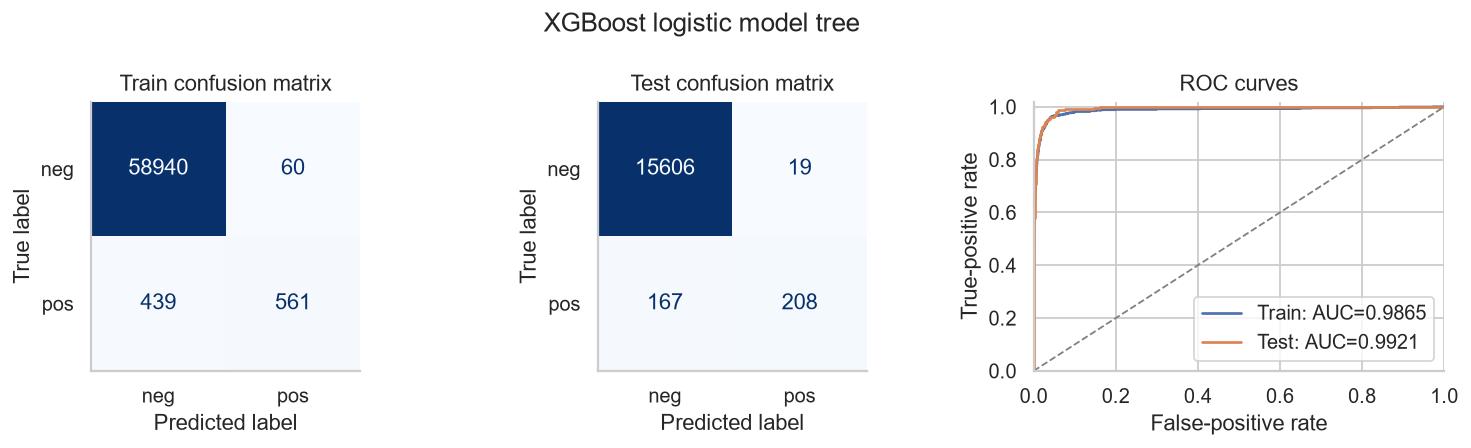

CV selects alpha = 0.0001: mean error 0.930% (fold SD 0.066%), versus test error 1.162%. The SD describes fold variability, not a confidence interval.

In [11]:
tree_plain_search, tree_plain_cv = tune_model_tree(False)
tree_plain = tree_plain_search.best_estimator_
tree_plain_results = evaluate_model('XGBoost logistic model tree', tree_plain)
selected = tree_plain_cv.iloc[tree_plain_search.best_index_]
display(Markdown(
    f'CV selects alpha = {selected.alpha:g}: mean error {selected.mean_CV_error:.3%} '
    f'(fold SD {selected.std_CV_error:.3%}), versus test error '
    f'{tree_plain_results.loc["Test", "error"]:.3%}. The SD describes fold variability, '
    'not a confidence interval.'))


### (f) SMOTE and the logistic model tree

SMOTE generates $z_{new}=z_i+u(z_{neighbor}-z_i)$, $u\sim U(0,1)$, using five minority neighbors after preprocessing. It adds 58,000 positives to all 60,000 original rows (118,000 total), retaining every negative.

Each fold fits preprocessing and SMOTE **only on training rows**: 48,000 originals become 94,400, leaving all 12,000 validation rows untouched. Resampling before splitting leaks related original/synthetic observations across folds. I retune alpha with (e)'s settings and evaluate training metrics on the original 60,000 rows. Interpolation may not preserve physical sensor relationships.

,alpha,mean_CV_AUC,mean_CV_error,std_CV_error,mean_CV_recall
0,0.000000,0.978952,0.044500,0.001761,0.956000
1,0.000100,0.979010,0.044417,0.001662,0.953000
2,0.001000,0.979998,0.045217,0.001657,0.952000
3,0.010000,0.978177,0.050800,0.001146,0.939000
4,0.100000,0.957650,0.063817,0.003120,0.884000


,error,ROC_AUC,recall_pos,precision_pos
Train,0.044100,0.988948,0.959000,0.269080
Test,0.042500,0.986569,0.965333,0.351798


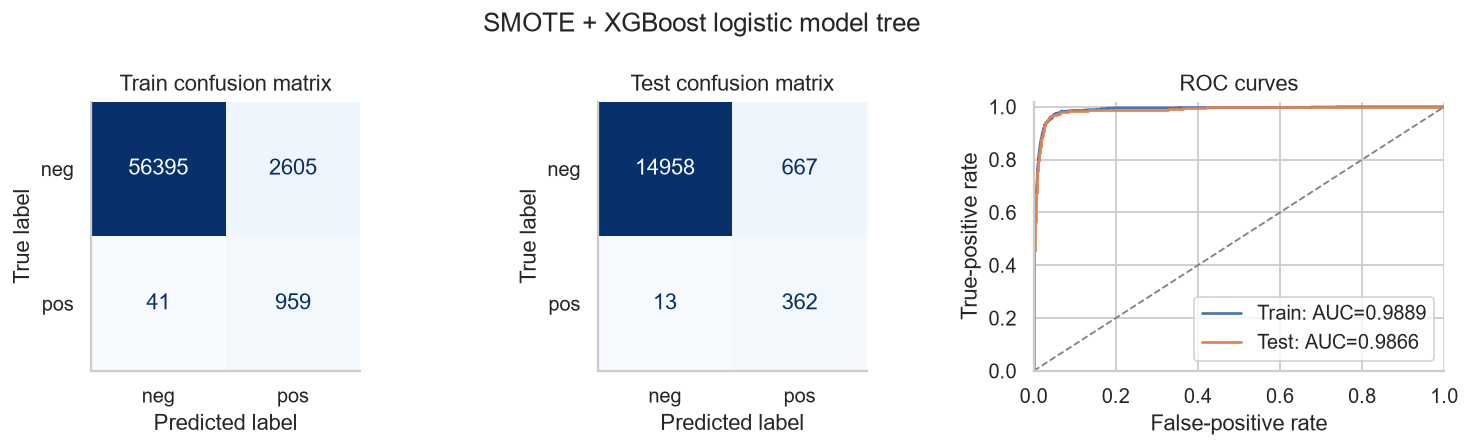

SMOTE selects alpha = 0.001: CV error 4.522% (fold SD 0.166%), versus test error 4.250%. Recall changes from 55.467% to 96.533%; missed failures change from 167 to 13, and false alarms change from 19 to 667. Precision changes from 91.630% to 35.180% and AUC from 0.9921 to 0.9866. These changes quantify the tradeoff between detecting failures and avoiding false alarms. SMOTE's altered class prior also means probabilities need not be calibrated to the original prevalence.

In [12]:
tree_smote_search, tree_smote_cv = tune_model_tree(True)
tree_smote = tree_smote_search.best_estimator_
synthetic_count = sum(tree_smote.named_steps['smote'].sampling_strategy_.values())
assert synthetic_count == 58000
assert all(len(t) == 48000 and y_train.iloc[t].sum() == 800 for t, _ in cv_splits)
tree_smote_results = evaluate_model('SMOTE + XGBoost logistic model tree', tree_smote)
selected = tree_smote_cv.iloc[tree_smote_search.best_index_]
a, b = tree_plain_results.loc['Test'], tree_smote_results.loc['Test']
display(Markdown(
    f'SMOTE selects alpha = {selected.alpha:g}: CV error {selected.mean_CV_error:.3%} '
    f'(fold SD {selected.std_CV_error:.3%}), versus test error {b.error:.3%}. '
    f'Recall changes from {a.recall_pos:.3%} to {b.recall_pos:.3%}; missed failures change '
    f'from {int(a.FN)} to {int(b.FN)}, and false alarms change from {int(a.FP)} to {int(b.FP)}. '
    f'Precision changes from {a.precision_pos:.3%} to {b.precision_pos:.3%} and '
    f'AUC from {a.ROC_AUC:.4f} to {b.ROC_AUC:.4f}. These changes quantify the '
    "tradeoff between detecting failures and avoiding false alarms. SMOTE's altered "
    'class prior also means probabilities '
    'need not be calibrated to the original prevalence.'))


#### Fitted model-tree structure

The table reports the fitted routing and terminal models. Predictions come from the terminal models. Where a root splits, its child counts sum to the root count; SMOTE counts include 58,000 synthetic positives. All 170 predictors are available at each node. Nonzero slopes exclude the intercept and describe the fitted model, not statistical significance.

In [13]:
node_rows = []
for label, pipeline in [('Uncompensated', tree_plain), ('SMOTE', tree_smote)]:
    for node in pipeline.named_steps['classifier'].nodes_:
        nonzero = (int(np.count_nonzero(node['model'].coef_))
                   if node['model'] is not None else 0)
        node_rows.append({'Model': label, 'Node': node['path'],
                          'Rows': node['rows'], 'Positive rows': node['positives'],
                          'Nonzero slopes': nonzero})
node_summary = pd.DataFrame(node_rows).set_index(['Model', 'Node'])
display(node_summary)


Rows  Positive rows  Nonzero slopes
Model         Node                                         
Uncompensated root     60000           1000             127
              root/L   59328            431             109
              root/R     672            569              86
SMOTE         root    118000          59000             117
              root/L   58336           2011              97
              root/R   59664          56989              95

#### Test-set comparison

All four models use the same official test observations, test-set median imputation, and a 0.5 decision threshold. Error, recall, and precision are percentages; ROC AUC uses the predicted probabilities.

In [14]:
model_labels = {'Random forest': 'Random forest',
                'Weighted random forest': 'Weighted RF',
                'XGBoost logistic model tree': 'Logistic tree',
                'SMOTE + XGBoost logistic model tree': 'SMOTE logistic tree'}
comparison = pd.DataFrame({model_labels[name]: result.loc['Test']
                           for name, result in all_results.items()}).T
comparison = comparison[['error', 'ROC_AUC', 'recall_pos', 'precision_pos', 'FP', 'FN']]
comparison.columns = ['Error', 'ROC AUC', 'Recall', 'Precision',
                      'False positives', 'False negatives']
display(comparison.style.format({'Error': '{:.3%}', 'ROC AUC': '{:.4f}',
                                  'Recall': '{:.2%}', 'Precision': '{:.2%}',
                                  'False positives': '{:.0f}', 'False negatives': '{:.0f}'}))
rf, smote = all_results['Random forest'].loc['Test'], tree_smote_results.loc['Test']
display(Markdown(
    f'{comparison["Error"].idxmin()} has the lowest test error; '
    f'{comparison["ROC AUC"].idxmax()} has the highest ROC AUC. '
    f'{comparison["Recall"].idxmax()} has the highest failure recall. '
    f'SMOTE misses {int(smote.FN)} failures '
    f'versus {int(rf.FN)} for the random forest, but generates {int(smote.FP)} false '
    f'alarms versus {int(rf.FP)}. The preferred model therefore depends on the '
    'relative costs of missed failures and false alarms.'))


,Error,ROC AUC,Recall,Precision,False positives,False negatives
Random forest,0.762%,0.9944,72.00%,94.08%,17,105
Weighted RF,1.069%,0.9931,58.13%,93.97%,14,157
Logistic tree,1.162%,0.9921,55.47%,91.63%,19,167
SMOTE logistic tree,4.250%,0.9866,96.53%,35.18%,667,13


Random forest has the lowest test error; Random forest has the highest ROC AUC. SMOTE logistic tree has the highest failure recall. SMOTE misses 13 failures versus 105 for the random forest, but generates 667 false alarms versus 17. The preferred model therefore depends on the relative costs of missed failures and false alarms.

## 2. ISLR 6.6.3

Increasing $s$ in $\sum_j|\beta_j|\le s$ relaxes lasso shrinkage. At $s=0$, only the unpenalized intercept remains.

| Part | Choice | Reason as $s$ increases |
|---|---|---|
| (a) Training RSS | **iv: decreases** | A larger feasible set lowers minimum RSS, then plateaus at least squares. |
| (b) Test RSS | **ii: decreases, then increases** | Bias reduction initially helps; increasing variance eventually hurts. |
| (c) Variance | **iii: increases** | Less shrinkage increases sensitivity to the sample. |
| (d) Squared bias | **iv: decreases** | Greater flexibility better approximates the true function. |
| (e) Irreducible error | **v: constant** | Data-generating noise is unchanged. |

RSS is nonincreasing; the other trends are qualitative expectations.

## 3. ISLR 6.6.5

Let $x_i=x_{i1}=x_{i2}$, $A=\sum_i x_i^2$, and $C=\sum_i x_i y_i$. Centering gives $\hat\beta_0=0$.

**(a)** Ridge minimizes $\sum_{i=1}^2[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2)$.

**(b)** For fixed $t=\beta_1+\beta_2$, the identity
$$\beta_1^2+\beta_2^2=\tfrac12t^2+\tfrac12(\beta_1-\beta_2)^2$$
forces $\beta_1=\beta_2=t/2$ when $\lambda>0$. Minimizing over $t$ yields
$$t^*=\frac{2C}{2A+\lambda},\qquad \boxed{\hat\beta_1=\hat\beta_2=\frac{C}{2A+\lambda}}.$$
At $\lambda=0$, duplicate columns make the coefficients nonunique; equality is not required.

**(c)** Lasso minimizes $\sum_{i=1}^2[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|)$.

**(d)** For fixed $t$, $|\beta_1|+|\beta_2|\ge|t|$, with equality for same-sign allocations. For $A>0$, minimizing over $t$ gives
$$t^*=\frac{\operatorname{sign}(C)(|C|-\lambda/2)_+}{A}.$$
If $t^*\ne0$, all $(\hat\beta_1,\hat\beta_2)=(a t^*,(1-a)t^*)$, $0\le a\le1$, have equal fitted values and objective, proving nonuniqueness. For $\lambda>0$ and $|C|\le\lambda/2$, only $(0,0)$ is optimal. At $\lambda=0$, any allocation of the optimal sum works, including opposite signs. If $A=0$ and $\lambda>0$, both coefficients are zero.

## 4. ISLR 8.4.5

**Majority vote: Red**, with six Red and four Green votes. **Average probability: Green**, since $\bar p_{Red}=4.5/10=0.45<0.5$. Probability averaging retains confidence information; hard voting gives each tree one equally weighted vote.

In [15]:
red_probabilities = np.array([.1, .15, .2, .2, .55, .6, .6, .65, .7, .75])
assert np.count_nonzero(red_probabilities > .5) == 6
assert np.isclose(red_probabilities.mean(), .45)


## 5. ISLR 9.7.3

**(a)** The seven observations are plotted below.

**(b)-(c)** The maximum-margin separator is $X_2=X_1-1/2$. With $(\beta_0,\beta_1,\beta_2)=(1/2,-1,1)$, predict **Red if $f(x)=1/2-X_1+X_2>0$**, Blue otherwise. Positive rescaling gives the same rule.

**(d)** The supporting lines $X_2=X_1$ and $X_2=X_1-1$ give margin $M=1/(2\sqrt2)\approx0.3536$ on each side (full width $1/\sqrt2$). The red hull segment from $(2,2)$ to $(4,4)$ and blue segment from $(2,1)$ to $(4,3)$ are parallel with overlapping projections and distance $1/\sqrt2$. No separator can exceed half this distance; the proposed line attains it.

**(e)** Support vectors: observations **2, 3, 5, 6**, at $(2,2)$, $(4,4)$, $(2,1)$, $(4,3)$.

**(f)** Observation 7, $(4,1)$, has $f(x)=-2.5$. A small move leaves its constraint inactive, so the supporting observations still determine the same optimum.

**(g)** $X_2=X_1-1/4$ also separates the data, but its closest-point margin is only $1/(4\sqrt2)$.

**(h)** Adding Blue $(2,3)$ destroys linear separability because it lies inside the red triangle:
$(2,3)=\tfrac14(3,4)+\tfrac12(2,2)+\tfrac14(1,4)$.
A linear score positive at those red vertices must be positive at their convex combination. The second plot shows this addition.

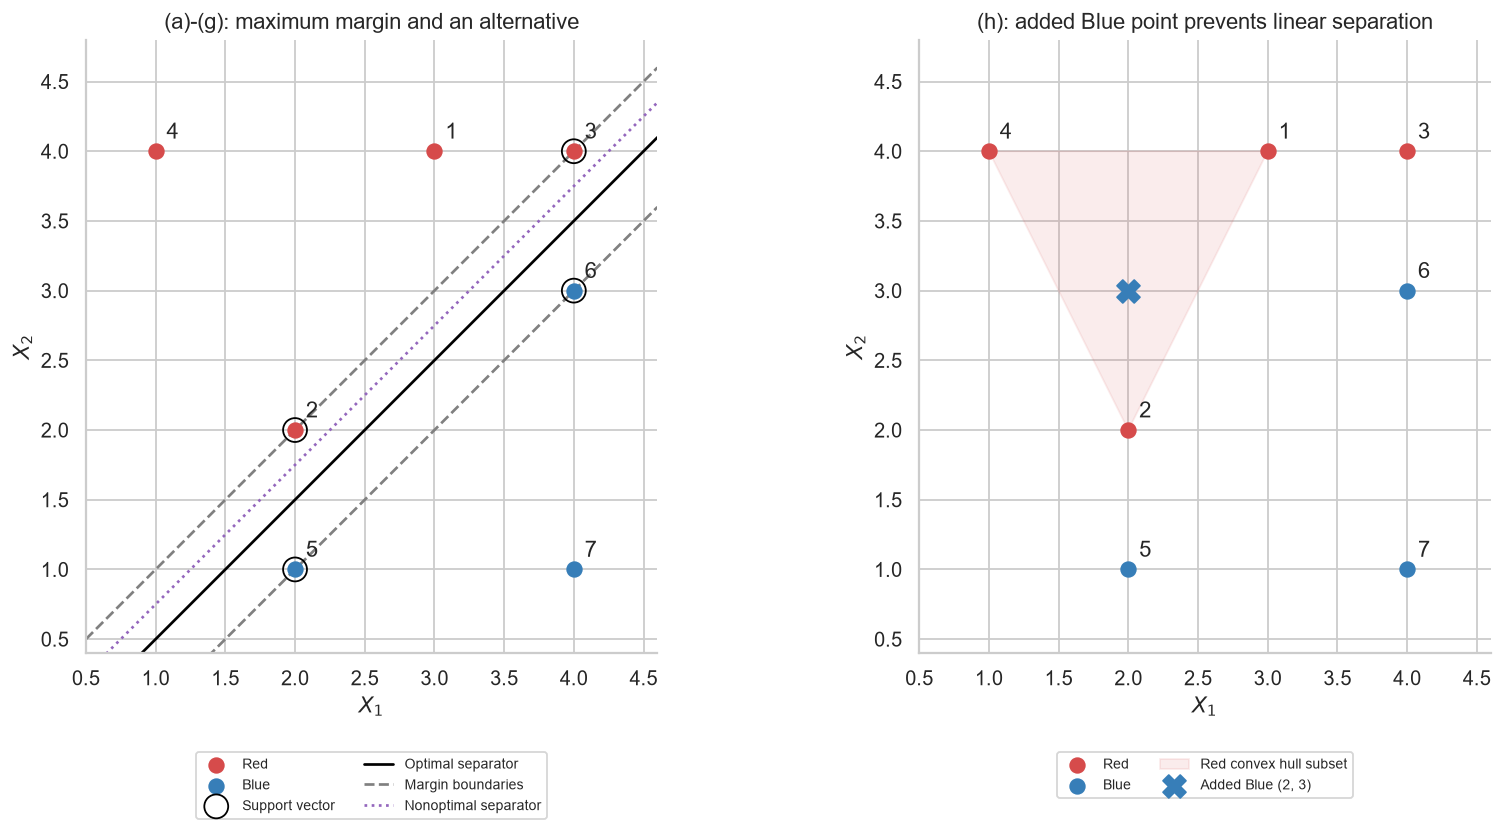

In [16]:
toy_X = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
toy_y = np.array([1, 1, 1, 1, -1, -1, -1])
signed_values = .5 - toy_X[:, 0] + toy_X[:, 1]
assert np.all(toy_y * signed_values > 0)
support = np.isclose(toy_y * signed_values, .5)
assert np.array_equal(np.where(support)[0] + 1, [2, 3, 5, 6])
line_x = np.linspace(.5, 4.6, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax in axes:
    for label, color, name in [(1, '#d64b4b', 'Red'), (-1, '#377eb8', 'Blue')]:
        points = toy_X[toy_y == label]
        ax.scatter(points[:, 0], points[:, 1], color=color, s=65, label=name, zorder=4)
    for i, (x, y) in enumerate(toy_X, 1):
        ax.annotate(str(i), (x, y), xytext=(6, 7), textcoords='offset points')
    ax.set(xlim=(.5, 4.6), ylim=(.4, 4.8), xlabel='$X_1$', ylabel='$X_2$')
    ax.set_aspect('equal')
axes[0].scatter(toy_X[support, 0], toy_X[support, 1], s=175,
                facecolors='none', edgecolors='black', label='Support vector', zorder=5)
axes[0].plot(line_x, line_x - .5, color='black', label='Optimal separator')
axes[0].plot(line_x, line_x, '--', color='gray', label='Margin boundaries')
axes[0].plot(line_x, line_x - 1, '--', color='gray')
axes[0].plot(line_x, line_x - .25, ':', color='#9467bd', label='Nonoptimal separator')
axes[0].set_title('(a)-(g): maximum margin and an alternative')
axes[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.15), ncol=2)
axes[1].fill([3, 2, 1], [4, 2, 4], color='#d64b4b', alpha=.1, label='Red convex hull subset')
axes[1].scatter([2], [3], marker='X', s=160, color='#377eb8', label='Added Blue (2, 3)', zorder=6)
axes[1].set_title('(h): added Blue point prevents linear separation')
axes[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.15), ncol=2)
plt.tight_layout()
plt.show()